# Superstore Sales & Return Analysis
**Sales performance, statistical evidence, and an honest test of return prediction**

A reproducible portfolio analysis of 1,500 transactions. This notebook connects descriptive sales patterns with supplied statistical results, then evaluates a separate logistic regression on held-out customers.

## 1. Project Overview
**Business question:** Which products and regions contribute to recorded sales, which transaction characteristics are associated with returns, and does the available information support useful return prediction?

1. Assess data quality and summarize transaction value, product mix, and regional performance.
2. Interpret the existing full-data statistical outputs without refitting completed inferential models.
3. Evaluate a fixed logistic regression pipeline against a simple baseline using customer-disjoint validation.

**Scope:** `TotalPrice` is recorded transaction value after discount. It includes transactions marked as returned and is not net revenue or profit. Currency, refunds, product costs, return dates, and return reasons are not documented.

**Run instructions:** Keep this notebook beside the repository CSVs. In Jupyter, start from that folder and select **Restart Kernel and Run All**. In Google Colab, upload the notebook and the four required CSVs, or clone the repository and change the working directory to the folder containing the files. No credentials, Drive mounting, or absolute paths are required. The loading cell includes a Colab upload prompt for the four required CSVs. No prepared-feature CSV is used.


## 2. Libraries and Data Loading
If imports fail in a fresh environment, run `%pip install pandas numpy matplotlib seaborn scikit-learn jinja2` in a separate cell, restart the kernel, and run all cells. Installed versions are recorded below.

The code below explicitly uses the four supplied CSVs. In Google Colab, if any are missing, it opens a file-upload dialog: select the four CSVs together. When the files already exist, uploads are skipped. Original data and model outputs are loaded separately; the analysis does not overwrite them.


In [ ]:
from pathlib import Path
from importlib.metadata import version
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, brier_score_loss,
    f1_score, make_scorer, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    StratifiedGroupKFold, StratifiedKFold, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_DIR = Path('.')  # Folder containing the notebook and CSVs.
THRESHOLD = 0.50  # Declared in advance; never tuned on the test set.
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 12,
    'axes.labelsize': 10, 'grid.alpha': 0.25,
})
BLUE, ORANGE, GRAY = '#315b7d', '#bc613d', '#84929b'
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 25)
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in
                 ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn']})
display(pd.Series(versions, name='Version').to_frame())


,Version
Python,3.13.18
pandas,2.2.3
numpy,2.1.3
matplotlib,3.10.0
seaborn,0.13.2
scikit-learn,1.6.1


In [ ]:
required_files = {
    'transactions': 'Product-Sales-Region.csv',
    'logit_results': 'return_logit_model_results.csv',
    'specifications': 'return_model_specification_summary.csv',
    'value_tests': 'stat_value_log_omnibus_tests.csv',
}

# Pointing directly to '/content' in Colab to reliably load your uploaded files
DATA_DIR = Path('/content')

missing_files = [name for name in required_files.values()
                 if not (DATA_DIR / name).is_file()]

if missing_files:
    try:
        from google.colab import files
    except ImportError as error:
        raise FileNotFoundError(
            f'Missing {missing_files}. In local Jupyter, place these CSVs beside '
            'the notebook or set DATA_DIR to their relative folder.'
        ) from error

    print('Select these CSV files in the upload dialog:')
    for filename in missing_files:
        print(f'  - {filename}')
    uploaded_files = files.upload()

    for filename in missing_files:
        destination = DATA_DIR / filename
        if not destination.is_file() and filename in uploaded_files:
            destination.write_bytes(uploaded_files[filename])
    del uploaded_files

missing_files = [name for name in required_files.values()
                 if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f'Still missing {missing_files}. Upload the exact filenames listed above, '
        'then rerun this cell. No prepared-feature CSV is needed.'
    )

raw_transactions = pd.read_csv(DATA_DIR / required_files['transactions'])
logit_results = pd.read_csv(DATA_DIR / required_files['logit_results'])
specification_results = pd.read_csv(DATA_DIR / required_files['specifications'])
value_tests = pd.read_csv(DATA_DIR / required_files['value_tests'])

loaded_files = {
    required_files['transactions']: raw_transactions,
    required_files['logit_results']: logit_results,
    required_files['specifications']: specification_results,
    required_files['value_tests']: value_tests,
}
display(pd.DataFrame([{'File': name, 'Rows': len(frame), 'Columns': frame.shape[1]}
                      for name, frame in loaded_files.items()]))
print('Transaction columns:', raw_transactions.columns.tolist())
display(raw_transactions[['Date', 'Region', 'Product', 'Quantity',
                          'TotalPrice', 'PaymentMethod', 'Returned']].head(3))

,File,Rows,Columns
0,Product-Sales-Region.csv,1500,19
1,return_logit_model_results.csv,22,14
2,return_model_specification_summary.csv,5,12
3,stat_value_log_omnibus_tests.csv,8,9


Transaction columns: ['Date', 'Region', 'Product', 'Quantity', 'UnitPrice', 'StoreLocation', 'CustomerType', 'Discount', 'Salesperson', 'TotalPrice', 'PaymentMethod', 'Promotion', 'Returned', 'OrderID', 'CustomerName', 'ShippingCost', 'OrderDate', 'DeliveryDate', 'RegionManager']


,Date,Region,Product,Quantity,TotalPrice,PaymentMethod,Returned
0,2023-02-23,East,Laptop,14.0,2290.400,Online,0.0
1,2024-12-19,South,Phone,1.0,544.010,Gift Card,0.0
2,2023-05-10,North,Desk,14.0,4361.868,Online,0.0


## 3. Data Quality Assessment
Inspect the original schema before conversion. Count invalid numeric/date values rather than silently interpreting them. Missing targets cannot be imputed. Exact duplicates are removed only from the analytical copy; conflicting order IDs stop the analysis for review.


In [ ]:
expected_columns = {
    'Date', 'Region', 'Product', 'Quantity', 'UnitPrice', 'StoreLocation',
    'CustomerType', 'Discount', 'TotalPrice', 'PaymentMethod', 'Promotion',
    'Returned', 'OrderID', 'CustomerName', 'OrderDate', 'DeliveryDate',
}
missing_columns = expected_columns - set(raw_transactions.columns)
if missing_columns:
    raise ValueError(f'Required columns unavailable: {sorted(missing_columns)}')
quality = pd.DataFrame({
    'dtype': raw_transactions.dtypes.astype(str),
    'missing': raw_transactions.isna().sum(),
    'missing_pct': raw_transactions.isna().mean().mul(100),
    'unique_nonmissing': raw_transactions.nunique(),
})
display(quality.round({'missing_pct': 2}))
print(f'Dimensions: {raw_transactions.shape[0]:,} rows x {raw_transactions.shape[1]} columns')
print(f'Exact duplicate rows: {raw_transactions.duplicated().sum():,}')
print(f'Duplicate order IDs: {raw_transactions.OrderID.duplicated().sum():,}')
print(f'Repeated nonmissing customer IDs: {raw_transactions.CustomerName.dropna().duplicated().sum():,}')


,dtype,missing,missing_pct,unique_nonmissing
Date,object,0,0.00,747
Region,object,0,0.00,5
Product,object,0,0.00,7
Quantity,float64,0,0.00,20
UnitPrice,float64,0,0.00,1482
StoreLocation,object,0,0.00,4
CustomerType,object,0,0.00,2
Discount,float64,0,0.00,4
Salesperson,object,0,0.00,6
TotalPrice,float64,0,0.00,1500


Dimensions: 1,500 rows x 19 columns
Exact duplicate rows: 0
Duplicate order IDs: 0
Repeated nonmissing customer IDs: 129


In [ ]:
transactions = raw_transactions.drop_duplicates().copy()
if transactions.OrderID.isna().any() or transactions.OrderID.duplicated().any():
    raise ValueError('Missing/conflicting OrderID values require review.')
numeric_columns = ['Quantity', 'UnitPrice', 'Discount', 'TotalPrice', 'Returned']
if 'ShippingCost' in transactions:
    numeric_columns.append('ShippingCost')
conversion_audit = []
for column in numeric_columns:
    converted = pd.to_numeric(transactions[column], errors='coerce')
    invalid = transactions[column].notna() & (converted.isna() | ~np.isfinite(converted))
    conversion_audit.append({'Field': column, 'Invalid values': int(invalid.sum())})
    transactions[column] = converted.where(np.isfinite(converted))
for column in ['Date', 'OrderDate', 'DeliveryDate']:
    converted = pd.to_datetime(transactions[column], errors='coerce')
    invalid = transactions[column].notna() & converted.isna()
    conversion_audit.append({'Field': column, 'Invalid values': int(invalid.sum())})
    transactions[column] = converted
display(pd.DataFrame(conversion_audit))
if (transactions.Returned.notna() & ~transactions.Returned.isin([0, 1])).any():
    raise ValueError('Returned must contain only 0, 1, or missing values.')
checks = pd.Series({
    'Missing total price': transactions.TotalPrice.isna().sum(),
    'Nonpositive total price': transactions.TotalPrice.le(0).sum(),
    'Nonpositive quantity': transactions.Quantity.le(0).sum(),
    'Negative unit price': transactions.UnitPrice.lt(0).sum(),
    'Discount outside [0, 1]': ((transactions.Discount < 0) | (transactions.Discount > 1)).sum(),
    'Delivery before order': (transactions.DeliveryDate < transactions.OrderDate).sum(),
    'Date differs from OrderDate': (transactions.Date.notna() & transactions.OrderDate.notna()
                                    & transactions.Date.ne(transactions.OrderDate)).sum(),
}, name='Count')
display(checks.to_frame())
if transactions.Quantity.le(0).any() or transactions.UnitPrice.lt(0).any():
    raise ValueError('Unexpected quantity/unit-price values require review.')
if ((transactions.Discount < 0) | (transactions.Discount > 1)).any():
    raise ValueError('Discount must be a fraction between 0 and 1.')
expected_value = transactions.Quantity * transactions.UnitPrice * (1 - transactions.Discount)
comparable = expected_value.notna() & transactions.TotalPrice.notna()
price_mismatches = ~np.isclose(transactions.loc[comparable, 'TotalPrice'],
                              expected_value[comparable], rtol=1e-9, atol=1e-6)
print(f'Quantity x price x (1 - discount) mismatches: {price_mismatches.sum():,}')
if transactions.TotalPrice.isna().any() or transactions.TotalPrice.le(0).any():
    raise ValueError('Sales totals/log values need valid positive TotalPrice; review first.')


,Field,Invalid values
0,Quantity,0
1,UnitPrice,0
2,Discount,0
3,TotalPrice,0
4,Returned,0
5,ShippingCost,0
6,Date,0
7,OrderDate,0
8,DeliveryDate,0


,Count
Missing total price,0
Nonpositive total price,0
Nonpositive quantity,0
Negative unit price,0
"Discount outside [0, 1]",0
Delivery before order,0
Date differs from OrderDate,0


Quantity x price x (1 - discount) mismatches: 0


**Observed quality:** The supplied dataset has no duplicate rows or duplicate order IDs. Only `Promotion` has missing values: 370 (24.7%). These records are retained. Missing promotion information does not establish that no promotion was used. The audit above exposes changes to these inputs on reruns.


## 4. Exploratory Data Analysis
Describe this sample rather than infer population-wide behavior. Transactions span January 2023 through June 2025, so annual totals would compare unequal observation periods. Monthly totals reflect recorded activity without adjustment for store size, operating days, or exposure.


In [ ]:
valid_targets = transactions.Returned.dropna()
summary = pd.Series({
    'Transactions': len(transactions), 'Units': transactions.Quantity.sum(min_count=1),
    'Recorded transaction value': transactions.TotalPrice.sum(min_count=1),
    'Mean transaction value': transactions.TotalPrice.mean(),
    'Median transaction value': transactions.TotalPrice.median(),
    'Recorded returns': valid_targets.sum(), 'Return rate (%)': 100 * valid_targets.mean(),
}, name='Value')
display(summary.to_frame().style.format('{:,.2f}').format(
    '{:,.0f}', subset=pd.IndexSlice[['Transactions', 'Units', 'Recorded returns'], ['Value']]
))
print('Observed transaction dates:', transactions.Date.min().date(),
      'through', transactions.Date.max().date())
display(transactions[['Quantity', 'UnitPrice', 'Discount', 'TotalPrice']].describe().round(2))
customer_summary = transactions.groupby('CustomerType', dropna=False).agg(
    transactions=('OrderID', 'size'), transaction_value=('TotalPrice', 'sum'),
    mean_value=('TotalPrice', 'mean'), return_rate=('Returned', 'mean'),
)
display(customer_summary.style.format({
    'transactions': '{:,}', 'transaction_value': '{:,.2f}',
    'mean_value': '{:,.2f}', 'return_rate': '{:.1%}',
}))


,Value
Transactions,"1,500"
Units,"15,616"
Recorded transaction value,"4,379,992.43"
Mean transaction value,"2,919.99"
Median transaction value,"2,174.72"
Recorded returns,372
Return rate (%),24.80


Observed transaction dates: 2023-01-01 through 2025-06-30


,Quantity,UnitPrice,Discount,TotalPrice
count,1500.00,1500.00,1500.00,1500.00
mean,10.41,298.83,0.07,2919.99
std,5.74,169.10,0.06,2522.79
min,1.00,5.52,0.00,6.97
25%,5.00,151.02,0.00,867.14
50%,11.00,294.74,0.05,2174.72
75%,15.00,446.70,0.10,4414.72
max,20.00,599.72,0.15,11077.00


,transactions,transaction_value,mean_value,return_rate
CustomerType,,,,
Retail,744,"2,195,525.59","2,950.98",25.4%
Wholesale,756,"2,184,466.84","2,889.51",24.2%


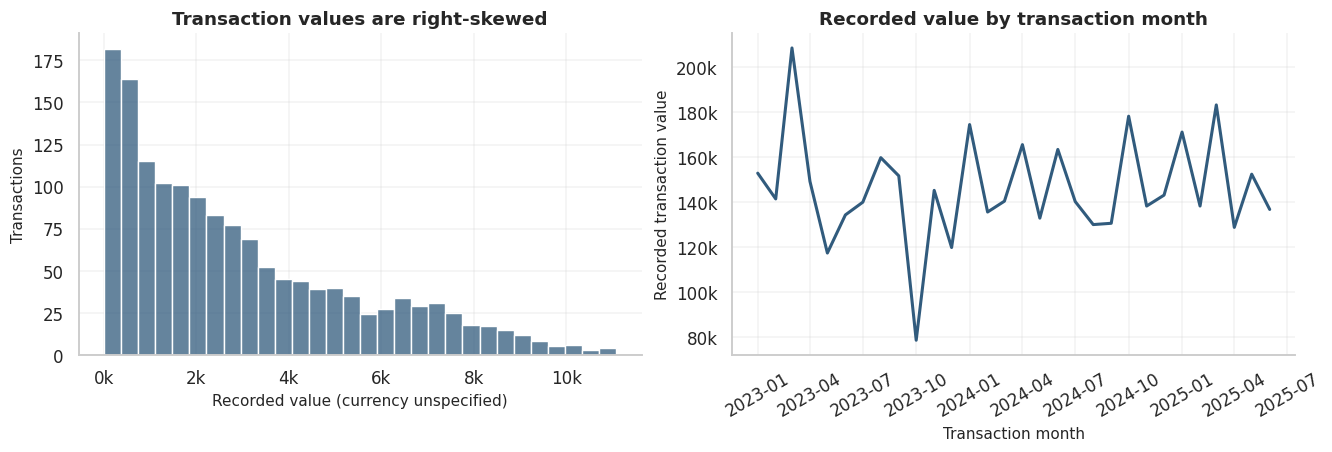

In [ ]:
monthly_value = (transactions.dropna(subset=['Date']).set_index('Date')
                 .TotalPrice.resample('MS').sum(min_count=1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
sns.histplot(data=transactions, x='TotalPrice', bins=30, color=BLUE, ax=axes[0])
axes[0].set(title='Transaction values are right-skewed',
            xlabel='Recorded value (currency unspecified)', ylabel='Transactions')
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1000:g}k'))
axes[1].plot(monthly_value.index, monthly_value.values, color=BLUE, linewidth=2)
axes[1].set(title='Recorded value by transaction month', xlabel='Transaction month',
            ylabel='Recorded transaction value')
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1000:.0f}k'))
axes[1].tick_params(axis='x', rotation=30)
plt.show()


## 5. Sales Performance Analysis
Compare total value alongside transaction count and average value. Regional rankings may reflect volume, transaction size, or both; store exposure is unavailable for productivity comparisons. Recorded sales include returned transactions and do not deduct refunds.


In [ ]:
def sales_summary(frame, group):
    result = frame.groupby(group, dropna=False).agg(
        transactions=('OrderID', 'size'), units=('Quantity', 'sum'),
        transaction_value=('TotalPrice', 'sum'), mean_value=('TotalPrice', 'mean'),
    ).sort_values('transaction_value', ascending=False)
    result['value_share'] = result.transaction_value / frame.TotalPrice.sum()
    return result

product_sales = sales_summary(transactions, 'Product')
regional_sales = sales_summary(transactions, 'Region')
for label, table in [('Product performance', product_sales), ('Regional performance', regional_sales)]:
    display(Markdown(f'**{label}**'))
    display(table.style.format({
        'transactions': '{:,}', 'units': '{:,.0f}', 'transaction_value': '{:,.2f}',
        'mean_value': '{:,.2f}', 'value_share': '{:.1%}',
    }))


**Product performance**

,transactions,units,transaction_value,mean_value,value_share
Product,,,,,
Tablet,240,"2,577","684,539.39","2,852.25",15.6%
Laptop,226,"2,408","684,417.24","3,028.39",15.6%
Printer,211,"2,336","684,387.42","3,243.54",15.6%
Monitor,212,"2,177","651,629.39","3,073.72",14.9%
Chair,209,"2,122","622,589.48","2,978.90",14.2%
Desk,207,"2,026","555,266.66","2,682.45",12.7%
Phone,195,"1,970","497,162.85","2,549.55",11.4%


**Regional performance**

,transactions,units,transaction_value,mean_value,value_share
Region,,,,,
North,309,"3,442","967,957.98","3,132.55",22.1%
East,311,"3,078","883,633.72","2,841.27",20.2%
West,284,"3,041","853,478.86","3,005.21",19.5%
Central,301,"3,102","847,153.68","2,814.46",19.3%
South,295,"2,953","827,768.19","2,805.99",18.9%


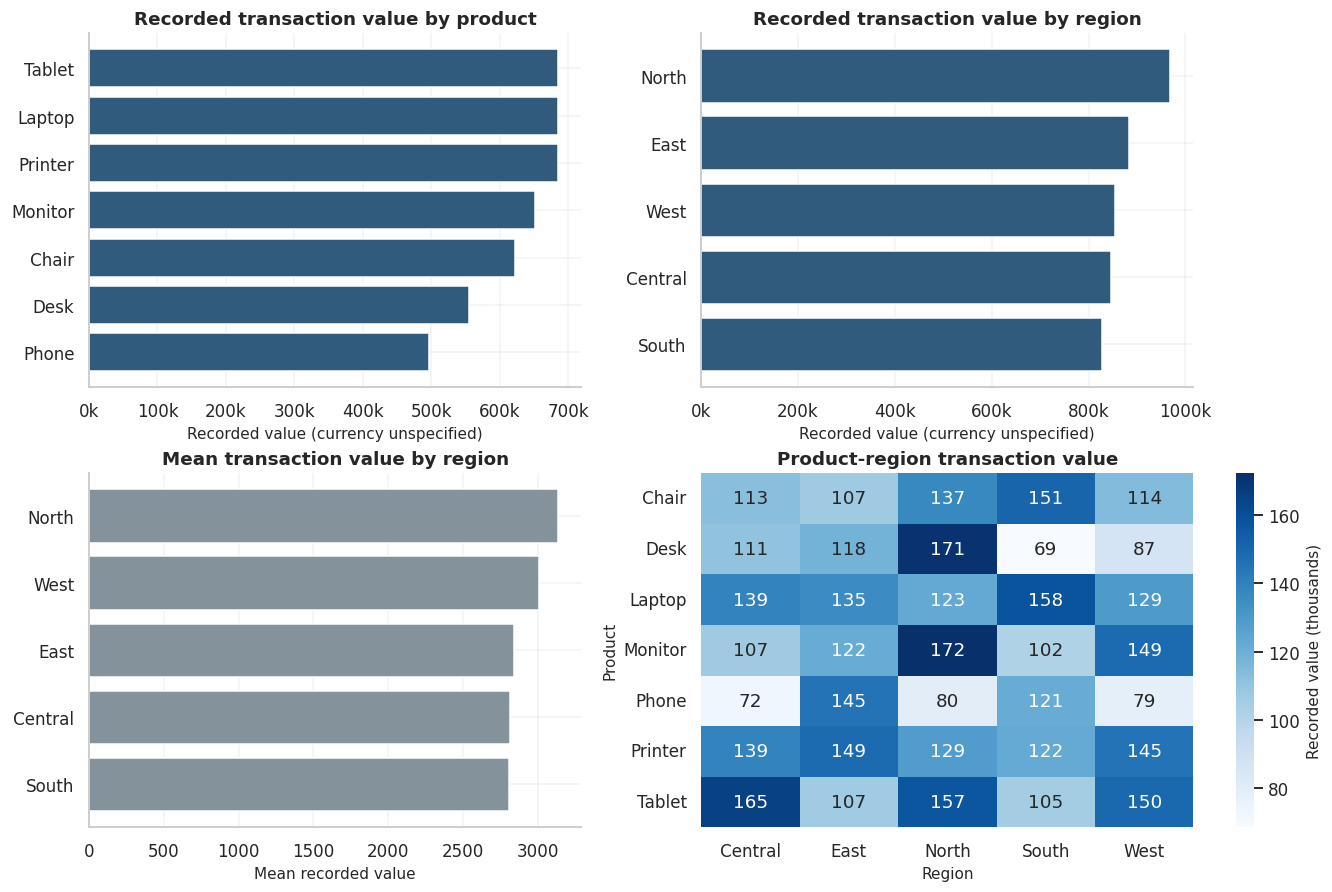

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
for table, ax, title in [
    (product_sales, axes[0, 0], 'Recorded transaction value by product'),
    (regional_sales, axes[0, 1], 'Recorded transaction value by region'),
]:
    ax.barh(table.index.astype(str), table.transaction_value, color=BLUE)
    ax.invert_yaxis()
    ax.set(title=title, xlabel='Recorded value (currency unspecified)')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x / 1000:.0f}k'))
region_means = regional_sales.mean_value.sort_values(ascending=False)
axes[1, 0].barh(region_means.index, region_means.values, color=GRAY)
axes[1, 0].invert_yaxis()
axes[1, 0].set(title='Mean transaction value by region', xlabel='Mean recorded value')
product_region = transactions.pivot_table(index='Product', columns='Region',
                                          values='TotalPrice', aggfunc='sum')
sns.heatmap(product_region / 1000, annot=True, fmt='.0f', cmap='Blues',
            cbar_kws={'label': 'Recorded value (thousands)'}, ax=axes[1, 1])
axes[1, 1].set(title='Product-region transaction value', xlabel='Region', ylabel='Product')
plt.show()


,transactions,returns,return_rate,ci_lower,ci_upper
PaymentMethod,,,,,
Cash,312,96,30.8%,25.9%,36.1%
Debit Card,290,78,26.9%,22.1%,32.3%
Online,323,77,23.8%,19.5%,28.8%
Credit Card,299,65,21.7%,17.4%,26.8%
Gift Card,276,56,20.3%,16.0%,25.4%


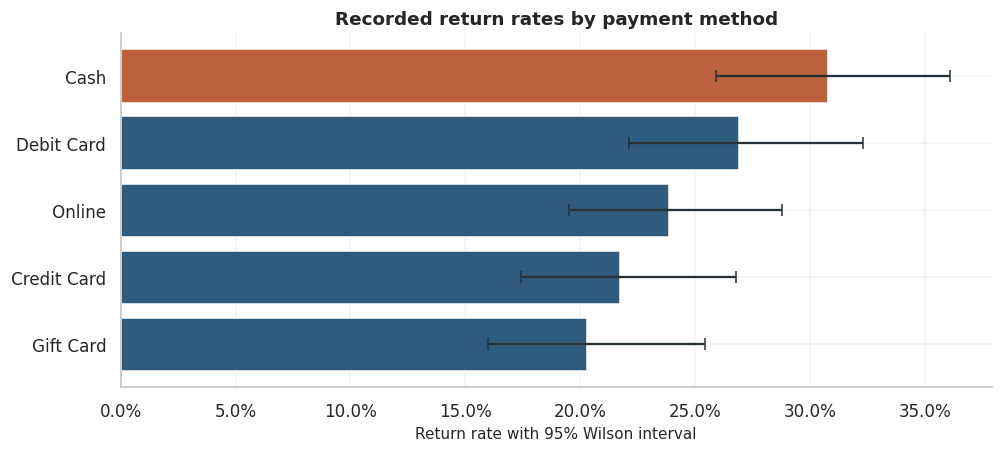

In [ ]:
# Wilson intervals describe uncertainty in unadjusted transaction-level rates.
payment_returns = transactions.groupby('PaymentMethod', dropna=False).agg(
    transactions=('OrderID', 'size'), labeled=('Returned', 'count'), returns=('Returned', 'sum'),
)
payment_returns['return_rate'] = payment_returns.returns / payment_returns.labeled
z = 1.959963984540054
n, p = payment_returns.labeled, payment_returns.return_rate
denominator = 1 + z**2 / n
center = (p + z**2 / (2 * n)) / denominator
half_width = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator
payment_returns['ci_lower'], payment_returns['ci_upper'] = center - half_width, center + half_width
payment_returns = payment_returns.sort_values('return_rate', ascending=False)
display(payment_returns[['transactions', 'returns', 'return_rate', 'ci_lower', 'ci_upper']]
        .style.format({'transactions': '{:,}', 'returns': '{:,.0f}',
                       'return_rate': '{:.1%}', 'ci_lower': '{:.1%}', 'ci_upper': '{:.1%}'}))
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
colors = [ORANGE if name == 'Cash' else BLUE for name in payment_returns.index]
ax.barh(payment_returns.index, payment_returns.return_rate, color=colors)
ax.errorbar(payment_returns.return_rate, np.arange(len(payment_returns)),
            xerr=np.vstack([payment_returns.return_rate - payment_returns.ci_lower,
                            payment_returns.ci_upper - payment_returns.return_rate]),
            fmt='none', ecolor='#263238', capsize=4)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='Recorded return rates by payment method', xlabel='Return rate with 95% Wilson interval')
plt.show()


Return-rate intervals are descriptive, unadjusted, and assume independent transactions. Repeat customers may make this assumption imperfect; these intervals are not pairwise significance tests. The supplied adjusted comparison is interpreted separately below.


## 6. Data Preparation
**Prediction-time assumption:** Product, region, customer type, store, payment method, discount, and transaction value are known at purchase. This requires operational verification. The target is recorded return status, with no defined return horizon.

Use the existing primary model's feature set. Compute only `LogTotalPrice`, a deterministic transform with no estimated parameters. Exclude delivery dates/duration, identifiers, and manager/salesperson labels. Promotion remains in descriptive analysis but is not in the primary-matched classifier.

**Validation design:** Use the first seeded stratified group fold as the holdout when customers repeat; each customer stays in one partition. If IDs are unique, use a stratified 80/20 split. Missing IDs are conservatively grouped together. Training-only cross-validation uses the same principle. No fold is selected based on scores.

Imputation, scaling, and one-hot encoding are fitted inside the pipeline on training data only. Outliers are retained; there is no test-derived cutoff, threshold tuning, or feature selection.


In [ ]:
categorical_features = ['PaymentMethod', 'Product', 'Region', 'CustomerType', 'StoreLocation']
numeric_features = ['Discount', 'LogTotalPrice']
model_data = transactions.loc[transactions.Returned.isin([0, 1])].copy()
print(f'Excluded rows with unavailable target: {len(transactions) - len(model_data):,}')
model_data['LogTotalPrice'] = np.log(model_data.TotalPrice)
X = model_data[categorical_features + numeric_features].copy()
for column in categorical_features:
    X[column] = X[column].astype(object).where(X[column].notna(), np.nan)
y = model_data.Returned.astype(int)
if y.nunique() != 2 or y.value_counts().min() < 10:
    raise ValueError('Insufficient labeled examples for binary validation.')
groups = model_data.CustomerName.fillna('__missing_customer__').astype(str)
use_groups = groups.duplicated().any()
if use_groups:
    holdout_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    train_positions, test_positions = next(holdout_splitter.split(X, y, groups))
else:
    train_positions, test_positions = train_test_split(
        np.arange(len(X)), test_size=0.20, stratify=y, random_state=RANDOM_STATE,
    )
X_train, X_test = X.iloc[train_positions].copy(), X.iloc[test_positions].copy()
y_train, y_test = y.iloc[train_positions].copy(), y.iloc[test_positions].copy()
groups_train, groups_test = groups.iloc[train_positions], groups.iloc[test_positions]
if use_groups:
    assert set(groups_train).isdisjoint(set(groups_test)), 'Customer leakage detected.'
assert set(X_train.index).isdisjoint(set(X_test.index))
if min(y_train.nunique(), y_test.nunique()) != 2:
    raise ValueError('Both classes are required in training and testing.')
display(pd.DataFrame({
    'Partition': ['Training', 'Test'], 'Transactions': [len(y_train), len(y_test)],
    'Return rate': [y_train.mean(), y_test.mean()],
    'Customers': [groups_train.nunique(), groups_test.nunique()],
}).set_index('Partition').style.format({'Return rate': '{:.1%}'}))
print('Split:', 'customer-disjoint stratified group fold' if use_groups else 'stratified random 80/20')
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scale', StandardScaler()),
    ]), numeric_features),
    ('categorical', Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='Missing', keep_empty_features=True)),
        ('encode', OneHotEncoder(handle_unknown='ignore')),
    ]), categorical_features),
])
return_classifier = Pipeline([
    ('preprocess', preprocessor),
    ('logistic', LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000, random_state=RANDOM_STATE)),
])


Excluded rows with unavailable target: 0


,Transactions,Return rate,Customers
Partition,,,
Training,1191,24.6%,1095
Test,309,25.6%,276


Split: customer-disjoint stratified group fold


## 7. Logistic Regression
Two distinct analyses answer different questions:

- **Existing inference:** Reuse the supplied full-data adjusted odds ratios and nominal confidence intervals without refitting. These are neither held-out predictive results nor causal effects.
- **New prediction benchmark:** Fit a regularized scikit-learn logistic regression with fixed features and `C=1`. Its penalized coefficients are not the supplied inferential estimates. No hyperparameters or thresholds are selected using test scores.


In [ ]:
required_logit_columns = {
    'row_type', 'readable_term', 'adjusted_odds_ratio', 'odds_ratio_ci_95_lower',
    'odds_ratio_ci_95_upper', 'p_value', 'sample_size', 'mcfadden_pseudo_r2',
}
if not required_logit_columns.issubset(logit_results.columns):
    raise ValueError('The supplied logistic-results schema has changed.')
cash_rows = logit_results.loc[logit_results.row_type.eq('term') &
                              logit_results.readable_term.eq('Cash versus Gift Card')]
if len(cash_rows) != 1:
    raise ValueError('Expected exactly one Cash-versus-Gift-Card coefficient.')
cash_result = cash_rows.iloc[0]
primary_rows = specification_results.loc[specification_results.specification.eq('primary')]
if len(primary_rows) != 1:
    raise ValueError('Expected one primary model specification.')
primary_specification = primary_rows.iloc[0]
assert np.isclose(cash_result.adjusted_odds_ratio, primary_specification.cash_odds_ratio)
if int(cash_result.sample_size) != len(model_data):
    raise ValueError('Current labeled sample does not match the supplied primary model.')
display(pd.DataFrame({'Estimate': [
    cash_result.adjusted_odds_ratio, cash_result.odds_ratio_ci_95_lower,
    cash_result.odds_ratio_ci_95_upper, cash_result.p_value, cash_result.mcfadden_pseudo_r2,
]}, index=['Cash vs Gift Card adjusted odds ratio', '95% CI lower', '95% CI upper',
          'Nominal p-value', 'McFadden pseudo-R²']).style.format('{:.4f}'))

cv_splitter = (StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
               if use_groups else StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE))
cv_splits = list(cv_splitter.split(X_train, y_train, groups_train if use_groups else None))
for fit_positions, validation_positions in cv_splits:
    assert y_train.iloc[fit_positions].nunique() == 2
    assert y_train.iloc[validation_positions].nunique() == 2
    if use_groups:
        assert set(groups_train.iloc[fit_positions]).isdisjoint(set(groups_train.iloc[validation_positions]))
scoring = {
    'roc_auc': 'roc_auc', 'average_precision': 'average_precision',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
}
cv_results = cross_validate(return_classifier, X_train, y_train, cv=cv_splits,
                            scoring=scoring, n_jobs=1, error_score='raise')
cv_summary = pd.DataFrame({
    'Mean': {name: cv_results[f'test_{name}'].mean() for name in scoring},
    'Fold SD': {name: cv_results[f'test_{name}'].std(ddof=1) for name in scoring},
})
display(Markdown('**Training-only five-fold validation (threshold 0.50)**'))
display(cv_summary.style.format('{:.3f}'))
return_classifier.fit(X_train, y_train)
if return_classifier.named_steps['logistic'].n_iter_.max() >= 2000:
    raise RuntimeError('Classifier reached its iteration limit; inspect convergence.')
baseline = DummyClassifier(strategy='prior', random_state=RANDOM_STATE)
baseline.fit(np.zeros((len(y_train), 1)), y_train)


,Estimate
Cash vs Gift Card adjusted odds ratio,1.7369
95% CI lower,1.1847
95% CI upper,2.5465
Nominal p-value,0.0047
McFadden pseudo-R²,0.0122


**Training-only five-fold validation (threshold 0.50)**

,Mean,Fold SD
roc_auc,0.483,0.031
average_precision,0.247,0.025
precision,0.000,0.000
recall,0.000,0.000
f1,0.000,0.000


DummyClassifier(random_state=42)

## 8. Model Evaluation
Evaluate the fitted pipeline once on the reserved test sample. The positive class is a recorded return. Precision, recall, and F1 use the predeclared 0.50 threshold; ROC-AUC and average precision use probabilities. Brier score measures probability error (lower is better). A baseline learns the training prevalence only.

This is a retrospective internal benchmark, not a future-return forecast: no return horizon or observation cutoff is supplied. Earlier full-sample analyses informed the documented feature set; an external/temporal sample is still needed for independent confirmation.


In [ ]:
test_probabilities = return_classifier.predict_proba(X_test)[:, 1]
baseline_probabilities = baseline.predict_proba(np.zeros((len(y_test), 1)))[:, 1]
def evaluate_probabilities(labels, probabilities):
    predictions = (probabilities >= THRESHOLD).astype(int)
    return {
        'Precision': precision_score(labels, predictions, zero_division=0),
        'Recall': recall_score(labels, predictions, zero_division=0),
        'F1': f1_score(labels, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(labels, probabilities),
        'Average precision': average_precision_score(labels, probabilities),
        'Brier score': brier_score_loss(labels, probabilities),
        'Predicted returns': int(predictions.sum()),
    }
test_metrics = pd.DataFrame({
    'Logistic regression': evaluate_probabilities(y_test, test_probabilities),
    'Training-prevalence baseline': evaluate_probabilities(y_test, baseline_probabilities),
}).T
display(test_metrics.style.format({
    **{column: '{:.3f}' for column in test_metrics.columns if column != 'Predicted returns'},
    'Predicted returns': '{:,.0f}',
}))
print(f'Test transactions: {len(y_test):,}; recorded returns: {y_test.sum():,}; prevalence: {y_test.mean():.1%}.')
print('Precision is reported as 0 when no returns are predicted (zero_division=0).')


,Precision,Recall,F1,ROC-AUC,Average precision,Brier score,Predicted returns
Logistic regression,0.000,0.000,0.000,0.549,0.308,0.190,0
Training-prevalence baseline,0.000,0.000,0.000,0.500,0.256,0.190,0


Test transactions: 309; recorded returns: 79; prevalence: 25.6%.
Precision is reported as 0 when no returns are predicted (zero_division=0).


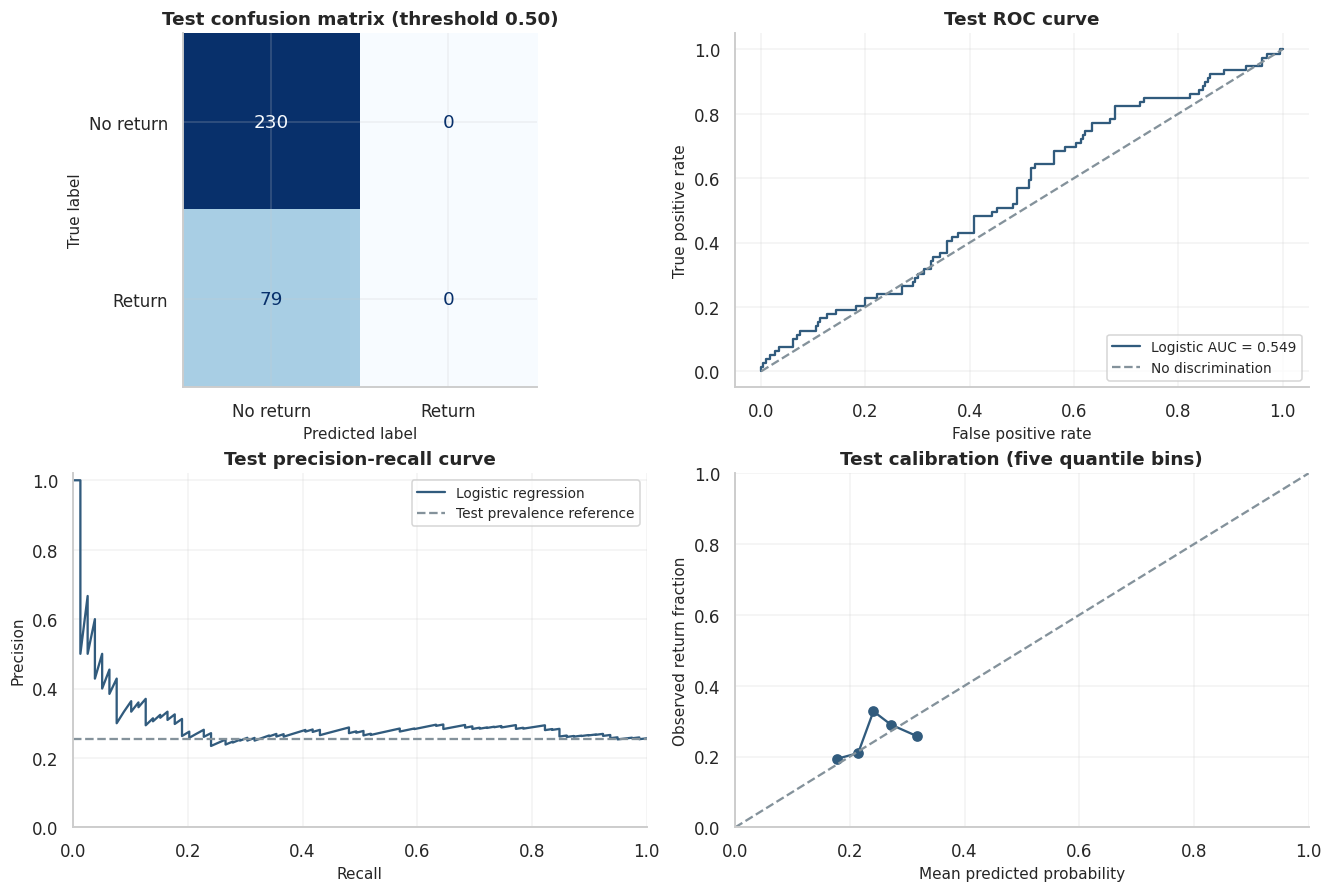

In [ ]:
test_predictions = (test_probabilities >= THRESHOLD).astype(int)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=[0, 1], display_labels=['No return', 'Return'],
    cmap='Blues', colorbar=False, ax=axes[0, 0], values_format='d',
)
axes[0, 0].set_title('Test confusion matrix (threshold 0.50)')
fpr, tpr, _ = roc_curve(y_test, test_probabilities)
axes[0, 1].plot(fpr, tpr, color=BLUE,
                label=f'Logistic AUC = {test_metrics.loc["Logistic regression", "ROC-AUC"]:.3f}')
axes[0, 1].plot([0, 1], [0, 1], '--', color=GRAY, label='No discrimination')
axes[0, 1].set(title='Test ROC curve', xlabel='False positive rate', ylabel='True positive rate')
axes[0, 1].legend(loc='lower right', fontsize=9)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_probabilities)
axes[1, 0].plot(recall_curve, precision_curve, color=BLUE, label='Logistic regression')
axes[1, 0].axhline(y_test.mean(), linestyle='--', color=GRAY, label='Test prevalence reference')
axes[1, 0].set(title='Test precision-recall curve', xlabel='Recall', ylabel='Precision',
                xlim=(0, 1), ylim=(0, 1.02))
axes[1, 0].legend(fontsize=9)
observed_fraction, predicted_mean = calibration_curve(y_test, test_probabilities, n_bins=5, strategy='quantile')
axes[1, 1].plot(predicted_mean, observed_fraction, 'o-', color=BLUE)
axes[1, 1].plot([0, 1], [0, 1], '--', color=GRAY)
axes[1, 1].set(title='Test calibration (five quantile bins)',
                xlabel='Mean predicted probability', ylabel='Observed return fraction',
                xlim=(0, 1), ylim=(0, 1))
plt.show()


In [ ]:
model_metrics = test_metrics.loc['Logistic regression']
base_metrics = test_metrics.loc['Training-prevalence baseline']
auc_assessment = ('does not improve on the 0.50 no-discrimination reference'
                  if model_metrics['ROC-AUC'] <= 0.50 else
                  'is above 0.50, but one small internal test is not deployment evidence')
brier_assessment = 'lower' if model_metrics['Brier score'] < base_metrics['Brier score'] else 'higher'
zero_prediction_note = (
    'At the default threshold the classifier flags no transactions, so it provides no return-case recall.'
    if model_metrics['Predicted returns'] == 0 else
    f'At the default threshold it flags {int(model_metrics["Predicted returns"])} transactions '
    f'and recalls {model_metrics["Recall"]:.1%} of recorded returns.'
)
display(Markdown(
    f'**Predictive interpretation:** Test ROC-AUC is **{model_metrics["ROC-AUC"]:.3f}** and '
    f'{auc_assessment}. Brier score is {brier_assessment} than the baseline '
    f'({model_metrics["Brier score"]:.3f} versus {base_metrics["Brier score"]:.3f}). '
    f'{zero_prediction_note} A significant full-data association does not guarantee useful classification. '
    'Thresholds should only be reconsidered with training/validation data and explicit review costs; '
    'they are not tuned after viewing test results. The calibration plot is descriptive and noisy at this sample size.'
))


**Predictive interpretation:** Test ROC-AUC is **0.549** and is above 0.50, but one small internal test is not deployment evidence. Brier score is lower than the baseline (0.190 versus 0.190). At the default threshold the classifier flags no transactions, so it provides no return-case recall. A significant full-data association does not guarantee useful classification. Thresholds should only be reconsidered with training/validation data and explicit review costs; they are not tuned after viewing test results. The calibration plot is descriptive and noisy at this sample size.

## 9. Statistical Analysis
The supplied omnibus tests concern **log transaction value**, not return status. The table preserves the reported tests and adds Benjamini–Hochberg adjustment across the eight omnibus tests as one exploratory family. This adjustment is a notebook addition, not part of the original export.


In [ ]:
required_test_columns = {'grouping_variable', 'test_used', 'statistic', 'p_value',
                         'sample_size', 'group_count', 'effect_size', 'effect_size_name'}
if not required_test_columns.issubset(value_tests.columns):
    raise ValueError('The supplied omnibus-test schema has changed.')
statistical_summary = value_tests.copy()
p_values = pd.to_numeric(statistical_summary.p_value, errors='raise').to_numpy()
if not np.isfinite(p_values).all() or ((p_values < 0) | (p_values > 1)).any():
    raise ValueError('Invalid omnibus p-values.')
order = np.argsort(p_values)
ranked_adjusted = p_values[order] * len(p_values) / np.arange(1, len(p_values) + 1)
ranked_adjusted = np.minimum.accumulate(ranked_adjusted[::-1])[::-1].clip(0, 1)
adjusted = np.empty_like(ranked_adjusted)
adjusted[order] = ranked_adjusted
statistical_summary['p_bh_8_tests'] = adjusted
columns = ['grouping_variable', 'test_used', 'statistic', 'p_value', 'p_bh_8_tests']
display(statistical_summary[columns].style.format({
    'statistic': '{:.3f}', 'p_value': '{:.4f}', 'p_bh_8_tests': '{:.4f}',
}))
specification_display = specification_results[[
    'specification', 'sample_size', 'cash_odds_ratio', 'cash_ci_95_lower',
    'cash_ci_95_upper', 'cash_p_value',
    'adjusted_cash_minus_gift_card_predicted_probability_difference',
]].copy().rename(columns={
    'adjusted_cash_minus_gift_card_predicted_probability_difference': 'adjusted_difference_pp'
})
specification_display['adjusted_difference_pp'] *= 100
display(Markdown('**Existing return-model sensitivity results (not held-out scores)**'))
display(specification_display.style.format({
    'sample_size': '{:,}', 'cash_odds_ratio': '{:.3f}', 'cash_ci_95_lower': '{:.3f}',
    'cash_ci_95_upper': '{:.3f}', 'cash_p_value': '{:.4f}', 'adjusted_difference_pp': '{:.2f}',
}))


,grouping_variable,test_used,statistic,p_value,p_bh_8_tests
0,PaymentMethod,Welch ANOVA on LogTotalPrice,2.533,0.0391,0.3030
1,PaymentMethod,Kruskal-Wallis robustness check on LogTotalPrice,8.472,0.0757,0.3030
2,CustomerType,Welch ANOVA on LogTotalPrice,0.049,0.8245,0.8245
3,CustomerType,Kruskal-Wallis robustness check on LogTotalPrice,0.182,0.6698,0.7655
4,Region,Welch ANOVA on LogTotalPrice,1.424,0.2242,0.3588
5,Region,Kruskal-Wallis robustness check on LogTotalPrice,4.456,0.3478,0.4637
6,Product,Welch ANOVA on LogTotalPrice,1.461,0.1892,0.3588
7,Product,Kruskal-Wallis robustness check on LogTotalPrice,10.147,0.1186,0.3163


**Existing return-model sensitivity results (not held-out scores)**

,specification,sample_size,cash_odds_ratio,cash_ci_95_lower,cash_ci_95_upper,cash_p_value,adjusted_difference_pp
0,primary,"1,500",1.737,1.185,2.547,0.0047,10.36
1,promotion sensitivity,"1,500",1.736,1.184,2.546,0.0047,10.37
2,no-store,"1,500",1.723,1.176,2.524,0.0053,10.21
3,raw-value,"1,500",1.735,1.183,2.544,0.0048,10.35
4,P99-excluded,"1,485",1.778,1.211,2.609,0.0033,10.83


**Interpretation:** Payment-method value differences have Welch ANOVA p = 0.0391, but Kruskal–Wallis p = 0.0757, so the finding is method-sensitive. None of the eight omnibus tests meets a 5% false-discovery threshold after the adjustment above. Customer-type, region, and product comparisons exceed 0.05 even before adjustment. This does not prove equivalence or test differences in sales totals.

For the separate return outcome, the supplied primary model reports adjusted Cash-versus-Gift-Card odds ratio 1.737 (nominal 95% CI 1.185–2.547, p = 0.00468). All five specifications report positive associations and intervals above 1. These are exploratory, model-conditional results: multiple coefficient inspection and unmeasured confounding limit confirmatory claims. Adjusted probability differences are reused as reported because their complete estimation procedure is not documented in the CSVs.


## 10. Visualizations
The sales, return-rate, and evaluation figures above answer distinct questions. This final figure summarizes sensitivity of the supplied adjusted association. Intervals describe odds ratios, not probability differences. The reference at 1 represents equal conditional odds.


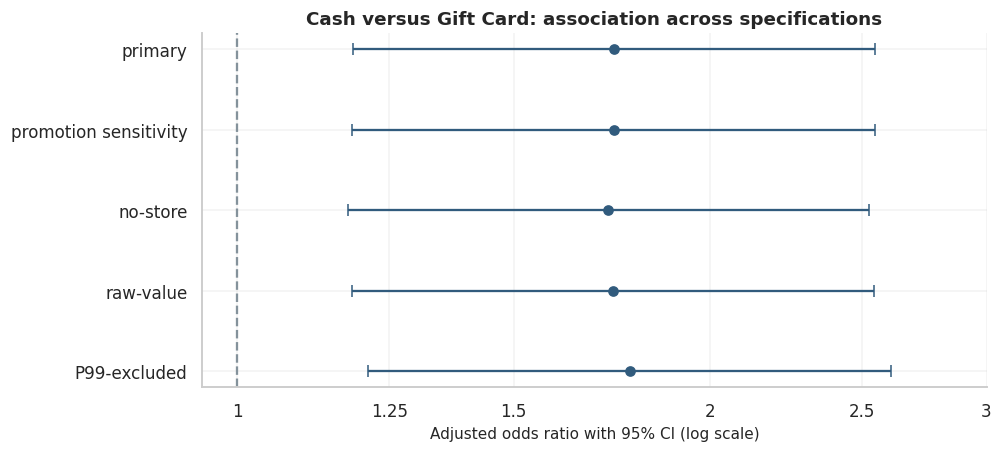

In [ ]:
forest = specification_results.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
positions = np.arange(len(forest))
ax.errorbar(forest.cash_odds_ratio, positions,
             xerr=np.vstack([forest.cash_odds_ratio - forest.cash_ci_95_lower,
                             forest.cash_ci_95_upper - forest.cash_odds_ratio]),
             fmt='o', color=BLUE, ecolor=BLUE, markersize=6, capsize=4)
ax.axvline(1, color=GRAY, linestyle='--', linewidth=1.5)
ax.set_yticks(positions, forest.specification)
ax.set_xscale('log')
ax.set_xticks([1, 1.25, 1.5, 2, 2.5, 3], ['1', '1.25', '1.5', '2', '2.5', '3'])
ax.set(xlim=(0.95, 3), title='Cash versus Gift Card: association across specifications',
        xlabel='Adjusted odds ratio with 95% CI (log scale)')
plt.show()


## 11. Key Findings
The following summary uses this run's results, keeping descriptive findings, supplied association estimates, and new validation metrics distinct.


In [ ]:
cash_rate = payment_returns.loc['Cash', 'return_rate']
gift_rate = payment_returns.loc['Gift Card', 'return_rate']
probability_differences = specification_results[
    'adjusted_cash_minus_gift_card_predicted_probability_difference'] * 100
leader_region, leader_product = regional_sales.index[0], product_sales.index[0]
display(Markdown(f'''
- **Sales:** Recorded value totals **{transactions.TotalPrice.sum():,.2f}** (currency unspecified), including returned transactions. **{leader_region}** has the largest regional total; **{leader_product}** has the largest product total.
- **Returns:** **{int(valid_targets.sum()):,} of {len(valid_targets):,}** labeled transactions are marked returned (**{valid_targets.mean():.1%}**). Cash is **{cash_rate:.1%}**, versus **{gift_rate:.1%}** for Gift Card: a **{100 * (cash_rate - gift_rate):.1f} percentage-point** observed gap.
- **Adjusted association:** The supplied odds ratio is **{cash_result.adjusted_odds_ratio:.2f}** (95% CI **{cash_result.odds_ratio_ci_95_lower:.2f}–{cash_result.odds_ratio_ci_95_upper:.2f}**). Reported adjusted probability differences range from **{probability_differences.min():.1f} to {probability_differences.max():.1f} percentage points** across specifications.
- **Prediction:** Held-out ROC-AUC is **{model_metrics['ROC-AUC']:.3f}**, precision **{model_metrics['Precision']:.3f}**, recall **{model_metrics['Recall']:.3f}**, and F1 **{model_metrics['F1']:.3f}** at threshold 0.50. Read these alongside the baseline and training-only validation.
- **Evidence limits:** Higher regional totals do not establish higher typical transaction values, causal payment effects, or profit. Product-region return differences are not established by the supplied main-effects models.
'''))



- **Sales:** Recorded value totals **4,379,992.43** (currency unspecified), including returned transactions. **North** has the largest regional total; **Tablet** has the largest product total.
- **Returns:** **372 of 1,500** labeled transactions are marked returned (**24.8%**). Cash is **30.8%**, versus **20.3%** for Gift Card: a **10.5 percentage-point** observed gap.
- **Adjusted association:** The supplied odds ratio is **1.74** (95% CI **1.18–2.55**). Reported adjusted probability differences range from **10.2 to 10.8 percentage points** across specifications.
- **Prediction:** Held-out ROC-AUC is **0.549**, precision **0.000**, recall **0.000**, and F1 **0.000** at threshold 0.50. Read these alongside the baseline and training-only validation.
- **Evidence limits:** Higher regional totals do not establish higher typical transaction values, causal payment effects, or profit. Product-region return differences are not established by the supplied main-effects models.


## 12. Business Recommendations

| Priority | Evidence and recommended action | Measure before changing policy |
| --- | --- | --- |
| Investigate Cash returns | The association survives five supplied specifications. Audit recording, return reasons, refunds, and comparable Cash/Gift Card workflows. | Verified return reasons, process exceptions, and refunds |
| Explain regional totals | Examine transaction volume and average value together; collect store exposure and capacity. | Value per store-day, comparable product mix, net realized revenue |
| Avoid unsupported subgroup targeting | Small cells and no supplied interaction analysis do not justify product-region payment policies. | Larger samples, intervals, and prespecified interaction tests |
| Establish financial impact | Collect item costs, refund amounts, partial-return quantities, and handling costs. | Net margin and incremental return costs |
| Validate prediction before use | Do not deploy on association strength. Define a return horizon and validate on later transactions with mature labels. | Discrimination, calibration, recall at feasible capacity, and net benefit |

These are proposed investigations, not implemented improvements or realized savings. Payment method should guide process investigation rather than automatically restrict customers.


## 13. Limitations and Future Work

- **Observational sample:** Associations do not establish causality. Provenance and sampling are undocumented; generalization is uncertain.
- **Return labels:** No return date, follow-up cutoff, reason, or partial-return information is supplied. Newer transactions may have less time to return. A future-return target needs a prediction date, outcome horizon, and mature labels.
- **Validation:** Customer grouping prevents identity overlap, but this historical split does not test future drift. Earlier supplied models used the full sample; this is exploratory internal evaluation. Fold SD is not a confidence interval.
- **Customer identity:** `CustomerName` is assumed to be a stable anonymized customer ID for grouping. Its consistency is undocumented. Transaction-level rate intervals do not adjust for customer clustering.
- **Feature timing:** Verify purchase-time availability of predictors before any operational use. Post-purchase delivery fields are excluded.
- **Profitability:** Recorded value includes transactions with returns. Currency, costs, refunds, and handling expenses are unavailable, preventing a profit/loss calculation.
- **Performance uncertainty:** The original model has low pseudo-R²; this is not the percentage of variation explained. A significant coefficient does not guarantee useful prediction. Small-sample calibration plots are noisy.
- **Missingness and subgroups:** Missing promotion information is retained without assuming its meaning. Product-region payment comparisons need larger samples and prespecified multiplicity-aware tests.
- **Reproducibility:** Inputs remain read-only. This notebook reproduces descriptive analysis and the new classifier, and reuses supplied inferential estimates. Original modeling code, exact sensitivity formulas, and the adjusted-probability procedure were not supplied; exact recreation of those exports is not claimed.

**Next steps:** Document provenance; establish a return observation window; collect operational and financial fields; validate on later data; investigate return-process causes; and evaluate interventions with a controlled operational study.

**Method references:** [scikit-learn guidance on leakage and pipelines](https://scikit-learn.org/stable/common_pitfalls.html) and [classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html). Package versions appear in Section 2.
